# Questão 1
Calcule a modularidade para a rede Jazz usando método fastgreedy.

In [ ]:
import networkx as nx
from networkx.algorithms.community import greedy_modularity_communities, modularity, louvain_communities

G= nx.read_edgelist("data/data/jazz.txt", nodetype=int)
G = G.to_undirected()
G.remove_edges_from(nx.selfloop_edges(G))
Gcc = sorted(nx.connected_components(G), key=len, reverse=True)
G = G.subgraph(Gcc[0])
G = nx.convert_node_labels_to_integers(G, first_label=0)

communities = list(greedy_modularity_communities(G))
modularity(G, communities)

0.4389078153753828

# Questão 2
Calcule a modularidade para a rede Jazz usando método Louvain.

In [7]:
communities = list(louvain_communities(G))
modularity(G, communities)

0.44412909167229275

# Questão 3
Considere o método de geração de redes LFR_benchmark_graph. Obtenha os valores da modularidade para μ=0.05,μ=0.1,μ=0.2. Use o algoritmo de Louvain.

In [14]:
N = 128
tau1 = 3
tau2 = 1.5
k = 16
minc = 32
maxc = 32

results = []
mus = [0.05, 0.1, 0.2]
for mu in mus:
    G = nx.LFR_benchmark_graph(n = N, tau1 = tau1, tau2 = tau2, mu = mu, min_degree = k, max_degree = k, min_community=minc, max_community = maxc, seed = 10)
    results.append(modularity(G, louvain_communities(G)))

results

[0.6507990505232746, 0.549582070125871, 0.4503933907867816]

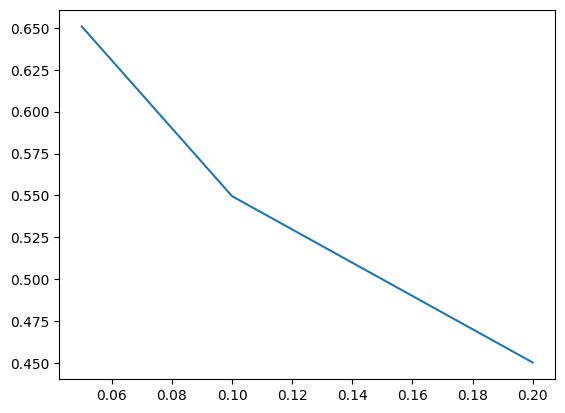

In [10]:
import matplotlib.pyplot as plt
plt.plot(mus, results)

# Questão 4
Considere o método de geração de redes LFR_benchmark_graph. Obtenha os valores da modularidade para μ=0.05,μ=0.1,μ=0.2. Use o algoritmo de fastgreedy.

In [16]:
N = 128
tau1 = 3
tau2 = 1.5
k = 16
minc = 32
maxc = 32

results = []
mus = [0.05, 0.2, 0.4]
for mu in mus:
    G = nx.LFR_benchmark_graph(n = N, tau1 = tau1, tau2 = tau2, mu = mu, min_degree = k, max_degree = k, min_community=minc, max_community = maxc, seed = 10)
    results.append(modularity(G, greedy_modularity_communities(G)))

results

[0.6507990505232746, 0.44042997085994173, 0.16430859354437072]

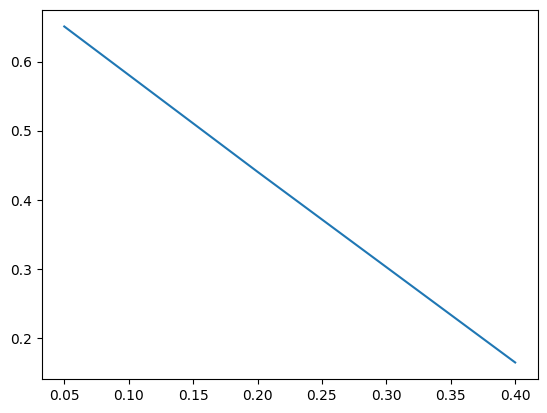

In [17]:
import matplotlib.pyplot as plt
plt.plot(mus, results)